# 04 – Elo Ratings

**Objective:** build overall and surface-specific Elo ratings, then check whether they predict matches better than ATP rankings.

**Key results (validation period, 2015–2021)**
- **Elo beats the ATP ranking:** the combined Elo has 66.21% accuracy and a log loss of 0.6103, against 65.01% and 0.6189 for the ranking.
- **Best settings:** a fixed $K$ of 32, with overall and surface ratings weighted equally.
- **Calibration:** probabilities are good but slightly overconfident for strong favourites.
- **Test period:** matches from 2023 onwards haven't been used to choose anything yet.

## 1. How Elo works

Every player has a rating, starting at 1500. Before a match, the two ratings give a win probability:

$$P(A \text{ wins}) = \frac{1}{1 + 10^{(R_B - R_A)/400}}$$

After the match, both ratings move by the same amount:

$$\text{change} = K \times (\text{result} - P)$$

The result is 1 for a win and 0 for a loss. An unexpected result moves ratings more than an expected one, and $K$ controls how fast ratings react.

## 2. Setup and evaluation periods

| Period | Used for |
|---|---|
| 2000–2004 | Warm-up: ratings need time to become meaningful, because everyone starts at 1500 |
| 2005–2014 | Fitting the ATP ranking benchmark |
| 2015–2021 | **Validation:** choosing the Elo settings and comparing methods |
| 2023 onwards | **Test:** deliberately not used here, and kept for the final evaluation |

Keeping the test period untouched gives an honest measure of performance later. If settings were chosen on those years, the final result would look better than it really is.

In [1]:
import sqlite3
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

DB_PATH = Path("../data/processed/tennis.db")
conn = sqlite3.connect(DB_PATH)

CHART_COLOR = "#2a78d6"
TEXT_COLOR = "#52514e"
GRID_COLOR = "#e4e3df"
REFERENCE_COLOR = "#8a8981"


def q(sql):
    """Run a SQL query and return the result as a DataFrame."""
    return pd.read_sql_query(sql, conn)

## 3. Put matches in chronological order

Elo has to process matches in the order they were played. The data has no match dates, so matches are sorted by tournament start date and then by round.

Walkovers are excluded, because no tennis was played. Matches that ended early, through retirement, default or abandonment, are flagged so we can test whether they should update ratings.

In [2]:
matches = q("""
SELECT
    m.tourney_id, m.match_num, m.round, m.score,
    m.winner_id, m.loser_id, m.winner_rank, m.loser_rank,
    t.surface, t.tourney_date,
    m.score LIKE '%RET%' OR m.score LIKE '%DEF%'
        OR m.score LIKE '%ABD%' OR m.score LIKE '%abandoned%'
        OR m.score LIKE '%unfinished%' AS ended_early
FROM matches AS m
JOIN tournaments AS t ON m.tourney_id = t.tourney_id
WHERE m.score NOT LIKE '%W/O%' AND m.score NOT LIKE '%Walkover%'
ORDER BY
    t.tourney_date,
    m.tourney_id,
    CASE m.round
        WHEN 'ER' THEN 0 WHEN 'RR' THEN 1 WHEN 'R128' THEN 2 WHEN 'R64' THEN 3
        WHEN 'R32' THEN 4 WHEN 'R16' THEN 5 WHEN 'QF' THEN 6 WHEN 'SF' THEN 7
        WHEN 'BR' THEN 8 WHEN 'F' THEN 9 ELSE 10
    END,
    m.match_num
""")
matches["year"] = matches["tourney_date"].str[:4].astype(int)

print(f"{len(matches):,} matches, {matches['ended_early'].sum():,} ended early")

78,876 matches, 2,395 ended early


## 4. The Elo function

**This loop is where data leakage is prevented.** For each match, the ratings are saved **first** and updated **afterwards**, so a match's stored rating never includes its own result.

Two choices for $K$ are tested:
- **Fixed:** the same value for everyone.
- **Variable:** $K = 250 / (n + 5)^{0.4}$, where $n$ is the player's number of previous matches. New players' ratings move quickly, and experienced players' ratings move slowly.

In [3]:
START_RATING = 1500


def win_probability(rating_a, rating_b):
    """Probability that the player rated rating_a beats the player rated rating_b."""
    return 1 / (1 + 10 ** ((rating_b - rating_a) / 400))


def variable_k(n_matches):
    return 250 / (n_matches + 5) ** 0.4


def fixed_k(value):
    return lambda n_matches: value


def run_elo(df, k_function, update_on_early_end=True):
    """Return each match's pre-match overall and surface ratings for both players."""
    overall = defaultdict(lambda: START_RATING)
    surface = defaultdict(lambda: START_RATING)
    overall_played = defaultdict(int)
    surface_played = defaultdict(int)
    rows = []

    for match in df.itertuples(index=False):
        winner, loser, court = match.winner_id, match.loser_id, match.surface
        has_surface = court is not None
        w_key, l_key = (winner, court), (loser, court)

        # Save the ratings BEFORE using this match's result
        rows.append((
            overall[winner], overall[loser],
            surface[w_key] if has_surface else np.nan,
            surface[l_key] if has_surface else np.nan,
        ))

        if match.ended_early and not update_on_early_end:
            continue

        # The winner's result is 1, so the winner gains exactly what the loser drops
        expected = win_probability(overall[winner], overall[loser])
        overall[winner] += k_function(overall_played[winner]) * (1 - expected)
        overall[loser] -= k_function(overall_played[loser]) * (1 - expected)
        overall_played[winner] += 1
        overall_played[loser] += 1

        if has_surface:
            expected = win_probability(surface[w_key], surface[l_key])
            surface[w_key] += k_function(surface_played[w_key]) * (1 - expected)
            surface[l_key] -= k_function(surface_played[l_key]) * (1 - expected)
            surface_played[w_key] += 1
            surface_played[l_key] += 1

    return pd.DataFrame(rows, columns=["winner_elo", "loser_elo", "winner_surface_elo", "loser_surface_elo"])

## 5. How predictions are scored

- **Accuracy:** how often the player given the higher probability won.
- **Log loss:** how good the probabilities are. It punishes confident mistakes heavily, and **lower is better**. For betting, this matters more than accuracy.

Each row holds the winner's probability, so a correct prediction is simply a probability above 0.5.

In [4]:
def score(winner_probability):
    """Accuracy and log loss, given the probability assigned to each match's winner."""
    p = np.clip(winner_probability, 1e-6, 1 - 1e-6)
    accuracy = np.where(p == 0.5, 0.5, p > 0.5).mean()
    return {"accuracy_pct": round(100 * accuracy, 2), "log_loss": round(-np.log(p).mean(), 4)}


validation = matches["year"].between(2015, 2021)
print(f"Validation matches: {validation.sum():,}")

Validation matches: 18,583


## 6. Choosing the Elo settings

Two settings are chosen together, on the validation period, by lowest log loss:

- **$K$:** how fast ratings react.
- **Overall weight $w$:** surface ratings capture specialists but rest on fewer matches, so a weighted average can use both.

$$\text{combined} = w \times \text{overall} + (1 - w) \times \text{surface}$$

In [5]:
settings = {
    "Fixed K = 16": fixed_k(16),
    "Fixed K = 24": fixed_k(24),
    "Fixed K = 32": fixed_k(32),
    "Fixed K = 48": fixed_k(48),
    "Variable K": variable_k,
}


def combined_probability(r, weight):
    """Winner's probability from a weighted mix of overall and surface Elo."""
    winner_surface = r["winner_surface_elo"].fillna(r["winner_elo"])
    loser_surface = r["loser_surface_elo"].fillna(r["loser_elo"])
    winner_mix = weight * r["winner_elo"] + (1 - weight) * winner_surface
    loser_mix = weight * r["loser_elo"] + (1 - weight) * loser_surface
    return win_probability(winner_mix, loser_mix)


results = []
for name, k_function in settings.items():
    candidate = run_elo(matches, k_function)
    for weight in [1.0, 0.75, 0.5, 0.25, 0.0]:
        p = combined_probability(candidate, weight)
        results.append({"setting": name, "overall_weight": weight, **score(p[validation])})

grid = pd.DataFrame(results).sort_values("log_loss")
BEST_SETTING = grid.iloc[0]["setting"]
BEST_WEIGHT = grid.iloc[0]["overall_weight"]
print(f"Best: {BEST_SETTING}, overall weight {BEST_WEIGHT}")
grid.head(8)

Best: Fixed K = 32, overall weight 0.5


,setting,overall_weight,accuracy_pct,log_loss
12,Fixed K = 32,0.50,66.22,0.6104
11,Fixed K = 32,0.75,65.92,0.6113
7,Fixed K = 24,0.50,65.80,0.6117
17,Fixed K = 48,0.50,66.15,0.6118
6,Fixed K = 24,0.75,65.76,0.6120
22,Variable K,0.50,66.42,0.6122
21,Variable K,0.75,66.26,0.6130
13,Fixed K = 32,0.25,65.85,0.6130


### Should matches that ended early update ratings?

A retirement often reflects an injury more than the level of play, so it may be misleading.

In [6]:
results = []
for label, update in [("Update on early end", True), ("Ignore early end", False)]:
    candidate = run_elo(matches, settings[BEST_SETTING], update_on_early_end=update)
    p = combined_probability(candidate, BEST_WEIGHT)
    results.append({"setting": label, **score(p[validation])})

pd.DataFrame(results)

,setting,accuracy_pct,log_loss
0,Update on early end,66.22,0.6104
1,Ignore early end,65.97,0.6119


In [7]:
# Final ratings used in the rest of this notebook
ratings = run_elo(matches, settings[BEST_SETTING])

## 7. Elo against the ATP ranking

Rankings don't produce a probability, so the benchmark is a small logistic regression that converts the ranking ratio into one. It is fitted on 2005–2014 and scored on the validation years.

All methods are compared on the same matches: those where both players have a different, known ranking.

In [8]:
def log_rank_ratio(df):
    return np.log(df["loser_rank"] / df["winner_rank"]).to_numpy().reshape(-1, 1)


has_ranks = (
    matches["winner_rank"].notna() & matches["loser_rank"].notna()
    & (matches["winner_rank"] != matches["loser_rank"])
)

# Each match appears from both players' points of view, so the model can't just learn "winner"
fit_rows = matches[has_ranks & matches["year"].between(2005, 2014)]
x = log_rank_ratio(fit_rows)
rank_model = LogisticRegression(fit_intercept=False)
rank_model.fit(np.vstack([x, -x]), np.r_[np.ones(len(x)), np.zeros(len(x))])

compare = validation & has_ranks
rank_p = rank_model.predict_proba(log_rank_ratio(matches[compare]))[:, 1]

comparison = pd.DataFrame([
    {"method": "ATP ranking", **score(rank_p)},
    {"method": "Overall Elo", **score(combined_probability(ratings, 1.0)[compare])},
    {"method": "Surface Elo", **score(combined_probability(ratings, 0.0)[compare])},
    {"method": "Combined Elo", **score(combined_probability(ratings, BEST_WEIGHT)[compare])},
])
print(f"Matches compared: {compare.sum():,}")
comparison.sort_values("log_loss")

Matches compared: 18,253


,method,accuracy_pct,log_loss
3,Combined Elo,66.21,0.6103
1,Overall Elo,65.65,0.6157
0,ATP ranking,65.01,0.6189
2,Surface Elo,65.24,0.6189


## 8. Are the probabilities trustworthy?

This is **calibration**: when the model says 70%, the favourite should win about 70% of the time. Points on the dashed line are perfectly calibrated.

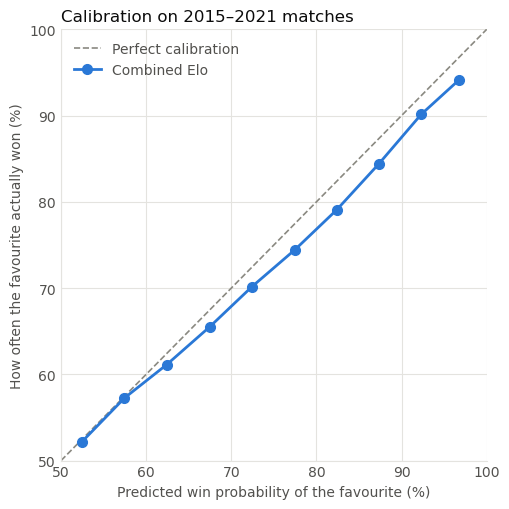

,n_matches,predicted,actual
0,3271,0.524,0.522
1,2990,0.575,0.573
2,2622,0.624,0.611
3,2375,0.675,0.655
4,2105,0.724,0.702
5,1722,0.775,0.744
6,1385,0.824,0.791
7,1031,0.873,0.844
8,741,0.923,0.901
9,341,0.967,0.941


In [9]:
p_winner = combined_probability(ratings, BEST_WEIGHT)[validation]
favourite_p = np.maximum(p_winner, 1 - p_winner)
favourite_won = p_winner > 0.5

calibration = pd.DataFrame({"predicted": favourite_p, "won": favourite_won})
calibration["bucket"] = pd.cut(calibration["predicted"], np.arange(0.5, 1.01, 0.05), include_lowest=True)
calibration = (
    calibration.groupby("bucket", observed=True)
    .agg(n_matches=("won", "size"), predicted=("predicted", "mean"), actual=("won", "mean"))
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([50, 100], [50, 100], color=REFERENCE_COLOR, linestyle="--", linewidth=1.2, label="Perfect calibration")
ax.plot(100 * calibration["predicted"], 100 * calibration["actual"], color=CHART_COLOR,
        linewidth=2, marker="o", markersize=7, label="Combined Elo")
ax.set_xlim(50, 100)
ax.set_ylim(50, 100)
ax.set_xlabel("Predicted win probability of the favourite (%)", color=TEXT_COLOR)
ax.set_ylabel("How often the favourite actually won (%)", color=TEXT_COLOR)
ax.set_title("Calibration on 2015–2021 matches", loc="left", fontsize=12, color="#0b0b0b")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRID_COLOR)
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=TEXT_COLOR, length=0)
ax.legend(frameon=False, labelcolor=TEXT_COLOR, loc="upper left")
plt.tight_layout()
plt.show()

calibration.round(3)

## 9. Save the ratings to the database

Every match gets its **pre-match** ratings, ready to become model features.

In [10]:
elo_table = pd.concat(
    [matches[["tourney_id", "match_num"]].reset_index(drop=True), ratings.round(2)], axis=1
)

conn.executescript("""
DROP TABLE IF EXISTS elo_ratings;

CREATE TABLE elo_ratings (
    tourney_id         TEXT NOT NULL,
    match_num          INTEGER NOT NULL,
    winner_elo         REAL NOT NULL,
    loser_elo          REAL NOT NULL,
    winner_surface_elo REAL,
    loser_surface_elo  REAL,
    PRIMARY KEY (tourney_id, match_num),
    FOREIGN KEY (tourney_id, match_num) REFERENCES matches (tourney_id, match_num)
);
""")
elo_table.to_sql("elo_ratings", conn, if_exists="append", index=False)
conn.commit()

q("SELECT COUNT(*) AS rows_saved FROM elo_ratings")

,rows_saved
0,78876


## 10. Sanity check: do the ratings look right?

### Strongest active players

`ROW_NUMBER() OVER (PARTITION BY ... ORDER BY ...)` is a **window function**. It numbers each player's matches separately, newest first, so `rn = 1` is the player's latest match. Unlike `GROUP BY`, it keeps every row. The rating shown is the one from before that match.

In [11]:
q("""
WITH player_matches AS (
    SELECT m.winner_id AS player_id, e.winner_elo AS elo, t.tourney_date, m.match_num
    FROM elo_ratings AS e
    JOIN matches AS m USING (tourney_id, match_num)
    JOIN tournaments AS t USING (tourney_id)
    UNION ALL
    SELECT m.loser_id, e.loser_elo, t.tourney_date, m.match_num
    FROM elo_ratings AS e
    JOIN matches AS m USING (tourney_id, match_num)
    JOIN tournaments AS t USING (tourney_id)
),
ranked AS (
    SELECT *, ROW_NUMBER() OVER (
        PARTITION BY player_id ORDER BY tourney_date DESC, match_num DESC
    ) AS rn
    FROM player_matches
)
SELECT p.name_first || ' ' || p.name_last AS player, r.elo, r.tourney_date AS last_tournament
FROM ranked AS r
JOIN players AS p ON r.player_id = p.player_id
WHERE r.rn = 1 AND r.tourney_date >= '2026-01-01'
ORDER BY r.elo DESC
LIMIT 10
""")

,player,elo,last_tournament
0,Jannik Sinner,2313.70,2026-05-25
1,Carlos Alcaraz,2203.63,2026-04-13
2,Novak Djokovic,2053.89,2026-05-25
3,Alexander Zverev,2024.05,2026-05-25
4,Arthur Fils,1975.71,2026-05-06
5,Jack Draper,1925.52,2026-04-13
6,Daniil Medvedev,1915.65,2026-05-25
7,Casper Ruud,1902.22,2026-05-25
8,Felix Auger Aliassime,1878.97,2026-05-25
9,Lorenzo Musetti,1877.78,2026-05-06


### Highest clay ratings ever reached

In [12]:
q("""
WITH clay_ratings AS (
    SELECT m.winner_id AS player_id, e.winner_surface_elo AS elo
    FROM elo_ratings AS e
    JOIN matches AS m USING (tourney_id, match_num)
    JOIN tournaments AS t USING (tourney_id)
    WHERE t.surface = 'Clay'
    UNION ALL
    SELECT m.loser_id, e.loser_surface_elo
    FROM elo_ratings AS e
    JOIN matches AS m USING (tourney_id, match_num)
    JOIN tournaments AS t USING (tourney_id)
    WHERE t.surface = 'Clay'
)
SELECT p.name_first || ' ' || p.name_last AS player, ROUND(MAX(c.elo)) AS peak_clay_elo
FROM clay_ratings AS c
JOIN players AS p ON c.player_id = p.player_id
GROUP BY c.player_id
ORDER BY peak_clay_elo DESC
LIMIT 5
""")

,player,peak_clay_elo
0,Rafael Nadal,2345.0
1,Novak Djokovic,2228.0
2,Andy Murray,2111.0
3,Roger Federer,2108.0
4,David Ferrer,2100.0


## 11. Conclusions

| Finding | Decision |
|---|---|
| Combined Elo scores best on both accuracy and log loss | Use it as the main strength feature |
| Combining the two ratings beats either one alone | Give the model overall and surface Elo |
| Updating ratings after early finishes scores slightly better (0.6104 vs 0.6119) | Keep retirements in the rating updates |
| Strong favourites win a little less often than predicted (77.5% predicted, 74.4% actual) | Recalibrate the probabilities in the modelling phase |

**Limits of these results**
- **Validation scores are slightly optimistic,** because the settings were chosen on the same years. The untouched test period will give the honest figure.
- **Match order is approximate,** because the data has only tournament start dates.
- **The improvement is real but modest.** Beating the ATP ranking doesn't mean beating bookmakers, whose odds already use far more information.
